<a href="https://colab.research.google.com/github/Daudicode12/Daudicode12/blob/main/Agrovault.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#importing the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile

# 4. Display configuration
print("AgroVault ML Environment Initialized!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

AgroVault ML Environment Initialized!
Pandas version: 2.2.3
NumPy version: 2.4.6


In [ ]:
#creating the folder to store our dataset
os.makedirs("content/data", exist_ok=True)


# 3. Confirm that the folder was created
print("AgroVault data workspace is ready!")
print("Dataset folder:", "/content/data")

AgroVault data workspace is ready!
Dataset folder: /content/data


In [ ]:
import os
# Let's search the environment to find where 'AgrovaultDataset.zip' is located
found_zips = []
for root, dirs, files in os.walk('/content'):
    for file in files:
        if 'agrovault' in file.lower() and file.endswith('.zip'):
            found_zips.append(os.path.join(root, file))

print("Found zip files:", found_zips if found_zips else "None. Please upload AgrovaultDataset.zip to your files sidebar.")

Found zip files: ['/content/content/data/AgrovaultDataset.zip']


In [ ]:

data_path = "/content/content/data"

#printing the otput
print("file found in the data folder")
print(os.listdir(data_path))

file found in the data folder
['AgrovaultDataset.zip', 'dxyvxk6h96-2']


In [ ]:
import zipfile
zip_path = "/content/content/data/AgrovaultDataset.zip"
extract_path = "/content/content/data"
zipfile.is_zipfile(zip_path)


with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

#printing the list of file in the content folder
print(os.listdir(extract_path))


['AgrovaultDataset.zip', 'dxyvxk6h96-2']


In [ ]:
import os

dataset_path = "/content/content/data/dxyvxk6h96-2"

print("Files inside the extracted dataset:")
for root, dirs, files in os.walk(dataset_path):
    for file in files:
        print(os.path.join(root, file))

Files inside the extracted dataset:
/content/content/data/dxyvxk6h96-2/LSCR.png
/content/content/data/dxyvxk6h96-2/museo.png
/content/content/data/dxyvxk6h96-2/November/4608daa8654c.txt
/content/content/data/dxyvxk6h96-2/November/Example_Tem01[11-02Wed].png
/content/content/data/dxyvxk6h96-2/November/bb3c32342d58.txt
/content/content/data/dxyvxk6h96-2/November/2e08daa8654c.txt
/content/content/data/dxyvxk6h96-2/November/1608daa8654c.txt
/content/content/data/dxyvxk6h96-2/November/ac07daa8654c.txt
/content/content/data/dxyvxk6h96-2/November/973c32342d58.txt
/content/content/data/dxyvxk6h96-2/November/description_table.png
/content/content/data/dxyvxk6h96-2/November/e61836342d58.txt
/content/content/data/dxyvxk6h96-2/November/ea3c32342d58.txt
/content/content/data/dxyvxk6h96-2/November/234132342d58.txt
/content/content/data/dxyvxk6h96-2/November/4d1736342d58.txt
/content/content/data/dxyvxk6h96-2/November/d61436342d58.txt
/content/content/data/dxyvxk6h96-2/November/d41636342d58.txt
/cont

In [ ]:
import os
from collections import Counter
dataset_path = "/content/content/dxyvxk6h96-2"
file_types = Counter()


for root, dirs, files in os.walk(dataset_path):
    for file in files:
        extension = os.path.splitext(file)[1].lower()
        file_types[extension] += 1

print("DATASET FILE TYPE SUMMARY")
print("-------------------------")

for extension, count in file_types.items():
    print(f"{extension or 'No extension'}: {count} files")

DATASET FILE TYPE SUMMARY
-------------------------


In [ ]:
# ==========================================
# AGROVAULT - INSPECT RAW SENSOR DATA
# ==========================================

import os

# 1. Define the dataset folder
dataset_path = "/content/content/data/adxyvxk6h96-2"

# 2. Find all TXT files in the dataset
txt_files = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith(".txt"):
            txt_files.append(os.path.join(root, file))

# 3. Check whether TXT files were found
if txt_files:

    # Select the first TXT file
    selected_file = txt_files[0]

    print("Selected file:", selected_file)
    print("\nFirst 30 lines of the file:")
    print("--------------------------------")

    # 4. Read and display the first 30 lines
    with open(selected_file, "r", encoding="utf-8", errors="replace") as f:
        for line_number, line in enumerate(f, start=1):
            if line_number > 30:
                break
            print(line.rstrip())

else:
    print("No TXT files found in the dataset folder.")

No TXT files found in the dataset folder.


In [ ]:
import pandas as pd
file_path = "/content/content/data/dxyvxk6h96-2/November/ea3c32342d58.txt"
df = pd.read_csv(file_path, sep=',', header=None)
print(df.head())

               0     1     2
0  1575262664640  58.1  19.7
1  1575262631596  58.0  19.6
2  1575262608938  58.0  19.6
3  1575262501653  58.1  19.5
4  1575262475634  58.1  19.7


In [ ]:
#labeling the columns
df.columns = ["timestamp", "humidity", "temperature"]
print(df.head())

       timestamp  humidity  temperature
0  1575262664640      58.1         19.7
1  1575262631596      58.0         19.6
2  1575262608938      58.0         19.6
3  1575262501653      58.1         19.5
4  1575262475634      58.1         19.7


In [ ]:
#converting the timestamp
df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)

In [ ]:
df = df.sort_values(by="timestamp").reset_index(drop=True)

In [ ]:
print(df.head())

                         timestamp  humidity  temperature
0 2019-11-01 05:00:13.152000+00:00      58.3         25.1
1 2019-11-01 05:00:33.121000+00:00      58.4         25.2
2 2019-11-01 05:00:54.867000+00:00      58.3         25.2
3 2019-11-01 05:01:26.176000+00:00      58.3         25.1
4 2019-11-01 05:01:57.119000+00:00      58.4         25.2


checking for the missing values

In [ ]:
print(df.isnull().sum())

timestamp      0
humidity       0
temperature    0
dtype: int64


In [ ]:
print(df[["temperature", "humidity"]].describe())

        temperature      humidity
count  57854.000000  57854.000000
mean      19.680549     60.795281
std        0.741382      4.868609
min       18.500000     44.500000
25%       19.300000     57.600000
50%       19.500000     59.500000
75%       19.800000     63.400000
max       26.800000     76.800000


In [ ]:
#checking for duplicate values
print(df.duplicated().sum())

0


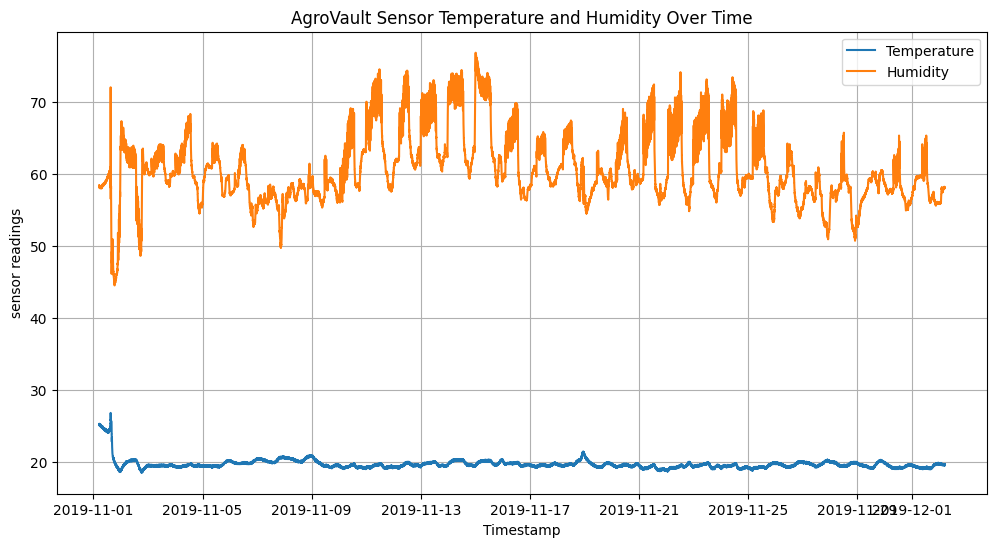

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plt.plot(df["timestamp"], df["temperature"], label="Temperature")
plt.plot(df["timestamp"], df["humidity"], label="Humidity")

plt.title("AgroVault Sensor Temperature and Humidity Over Time")

plt.xlabel("Timestamp")
plt.ylabel("sensor readings")

plt.legend()

plt.grid(True)

plt.show()


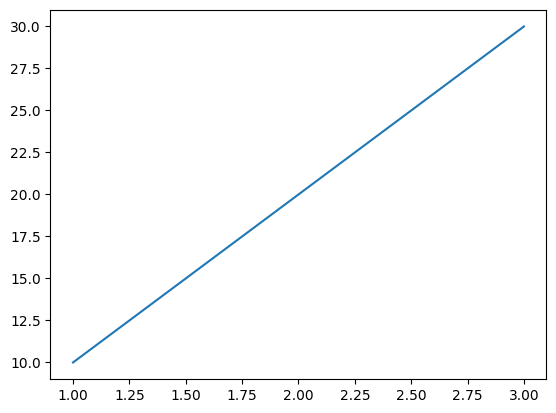

In [ ]:
plt.plot([1, 2, 3], [10, 20, 30])
plt.show()

In [ ]:
print(df[["temperature", "humidity"]].corr())

             temperature  humidity
temperature     1.000000 -0.081434
humidity       -0.081434  1.000000


In [ ]:
#This calculates the time difference between consecutive readings
print(df["timestamp"].diff().describe())

count                        57853
mean     0 days 00:00:46.294081344
std      0 days 00:00:51.450786281
min         0 days 00:00:03.116000
25%         0 days 00:00:15.359000
50%         0 days 00:00:30.268000
75%         0 days 00:00:58.245000
max         0 days 00:26:38.763000
Name: timestamp, dtype: object


In [ ]:
print((df["timestamp"].diff() > pd.Timedelta(minutes=5)).sum())

287


In [ ]:
gaps = df["timestamp"].diff()

print(df.loc[gaps > pd.Timedelta(minutes=5), ["timestamp"]].assign(gap=gaps[gaps > pd.Timedelta(minutes=5)]).nlargest(5, "gap"))

                            timestamp                    gap
898  2019-11-01 15:52:47.199000+00:00 0 days 00:26:38.763000
6566 2019-11-05 18:30:45.583000+00:00 0 days 00:19:58.834000
6686 2019-11-06 00:37:46.791000+00:00 0 days 00:16:16.448000
4621 2019-11-04 12:14:49.505000+00:00 0 days 00:14:38.008000
6552 2019-11-05 17:16:45.409000+00:00 0 days 00:13:08.007000


In [ ]:
print("Start:", df["timestamp"].min(), "\nEnd:", df["timestamp"].max(), "\nDuration:", df["timestamp"].max() - df["timestamp"].min())

Start: 2019-11-01 05:00:13.152000+00:00 
End: 2019-12-02 04:57:44.640000+00:00 
Duration: 30 days 23:57:31.488000


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
humidity,57854.0,60.795281,4.868609,44.5,57.6,59.5,63.4,76.8
temperature,57854.0,19.680549,0.741382,18.5,19.3,19.5,19.8,26.8


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
